# 딥러닝 기초 2일차 실습과제: MLP와 옵티마이저

## 과제 개요
이 과제에서는 실제 의료 데이터를 활용하여 **다층 퍼셉트론(MLP)**을 구현하고, 다양한 **옵티마이저**의 성능을 비교합니다.

### 사용 데이터셋
- **Pima Indians Diabetes Database**
- 768명의 환자 데이터, 8개의 의료 특성
- 목표: 당뇨병 여부 예측 (이진 분류)

### 학습 목표
1. PyTorch로 MLP 모델 구현
2. 순전파와 손실함수 이해
3. 다양한 옵티마이저(SGD, Adam) 비교
4. 학습 곡선 분석

### 예상 소요 시간
약 **1시간**

---

> 📝 **작성자**: 조태희 · OZ 코딩 스쿨 AI 헬스케어 부트캠프 6기
> ▶️ **실행 방법**: Colab 왼쪽 `파일` 탭에 `diabetes.csv`를 올린 뒤(또는 아래 업로드 셀에서 선택) `런타임 → 모두 실행`을 누르세요. 이 노트북의 학습은 CPU에서도 수십 초 안에 끝납니다.
> 📌 노션 2일차 페이지의 **(필수) 과제 "PyTorch 학습 루프 코드 필사"**는 맨 아래 **Part 6**에 있습니다.

## Part 0: 환경 설정

In [1]:
# 필요한 라이브러리 import
import torch                                        # 파이토치 본체: 텐서(다차원 배열) 연산 + 자동 미분
import torch.nn as nn                               # 신경망 층(Linear, ReLU 등)과 손실 함수 모음
import torch.optim as optim                         # 옵티마이저(SGD, Adam 등) 모음
from torch.utils.data import DataLoader, TensorDataset  # 데이터를 (입력, 정답) 쌍으로 묶고 배치로 나눠 주는 도구

import numpy as np                                  # 수치 계산
import pandas as pd                                 # 표(DataFrame) 데이터 다루기
import matplotlib.pyplot as plt                     # 그래프
from sklearn.preprocessing import StandardScaler    # 특성 표준화(평균 0, 표준편차 1) 도구
from sklearn.model_selection import train_test_split  # 학습/테스트 데이터 나누기
from sklearn.metrics import accuracy_score          # 정확도 계산 함수

# 재현성을 위한 시드 설정
torch.manual_seed(42)  # 파이토치 난수 고정 → 가중치 초기값, 배치 섞는 순서가 매번 같아짐
np.random.seed(42)     # numpy 난수 고정

# GPU 사용 가능 여부 확인
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')  # GPU가 있으면 cuda, 없으면 cpu
print(f'Using device: {device}')  # 어떤 장치를 쓸 수 있는지 출력 (이 과제의 학습 함수는 CPU에서 동작)

Using device: cpu


## Part 1: 데이터 준비

In [2]:
# 📁 [Colab 준비] diabetes.csv 업로드 도우미
# Colab의 기본 작업 폴더는 /content 입니다. 이미 /content/diabetes.csv 가 있으면 이 셀은 그냥 통과합니다.
import os  # 파일 존재 여부를 확인하기 위한 표준 라이브러리

if not os.path.exists('diabetes.csv'):            # 현재 폴더에 diabetes.csv가 없다면
    try:
        from google.colab import files            # Colab에서만 쓸 수 있는 파일 업로드 도구
        print('diabetes.csv 파일을 선택해 업로드해 주세요.')
        files.upload()                            # 업로드 창이 뜸 → 올린 파일은 /content 에 저장됨
    except ImportError:                           # Colab이 아닌 환경(로컬 주피터 등)이라면
        raise FileNotFoundError('diabetes.csv를 이 노트북과 같은 폴더에 넣어 주세요.')
print('diabetes.csv 준비 완료:', os.path.exists('diabetes.csv'))  # True가 나오면 준비 끝

diabetes.csv 준비 완료: True


In [3]:
# ============================================
# 데이터 로드
# diabetes.csv 파일을 노트북과 같은 폴더에 업로드하세요
# ============================================

df = pd.read_csv('diabetes.csv')                  # CSV 파일을 표(DataFrame)로 읽기

print(f"데이터셋 크기: {df.shape}")                 # (행 수, 열 수) = (환자 수, 컬럼 수)
print(f"\n특성 목록: {list(df.columns)}")           # 컬럼 이름 목록
print(f"\n타겟 분포:")                              # 정답(Outcome) 분포 제목
print(df['Outcome'].value_counts())                # 0(당뇨 아님) / 1(당뇨) 각각의 인원 수

df.head()                                          # 앞 5줄 미리보기 (셀 마지막 줄이라 표로 출력됨)

데이터셋 크기: (768, 9)

특성 목록: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

타겟 분포:
Outcome
0    500
1    268
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
# 데이터 전처리
X = df.drop('Outcome', axis=1).values   # 입력(X): 정답 컬럼을 뺀 8개 특성 → numpy 배열
y = df['Outcome'].values                # 정답(y): Outcome (0 또는 1)

# Train/Test 분할 (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y   # 20%는 시험용 / stratify=y: 두 세트의 당뇨 비율을 원본과 같게 유지
)

# 정규화
scaler = StandardScaler()                         # 각 특성을 평균 0, 표준편차 1로 맞추는 도구
X_train_scaled = scaler.fit_transform(X_train)    # 학습 데이터로 평균·표준편차를 '배우고(fit)' 바로 변환
X_test_scaled = scaler.transform(X_test)          # 테스트는 학습 데이터 기준으로 '변환만' → 테스트 정보가 학습에 새지 않음

# PyTorch Tensor로 변환
X_train_tensor = torch.FloatTensor(X_train_scaled)          # numpy → 32비트 실수 텐서 (모양: [샘플 수, 8])
y_train_tensor = torch.FloatTensor(y_train).unsqueeze(1)    # [샘플 수] → [샘플 수, 1] : 모델 출력 모양과 맞춤
X_test_tensor = torch.FloatTensor(X_test_scaled)            # 테스트 입력 텐서
y_test_tensor = torch.FloatTensor(y_test).unsqueeze(1)      # 테스트 정답 텐서

# DataLoader 생성
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)   # (입력, 정답) 쌍으로 묶은 데이터셋
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)      # 테스트용 데이터셋

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)   # 32개씩 공급, 에폭마다 순서 섞기
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)    # 평가는 순서를 섞을 필요 없음

print(f"Train: {len(X_train)} samples")          # 학습 샘플 수
print(f"Test: {len(X_test)} samples")            # 테스트 샘플 수
print(f"Input features: {X_train.shape[1]}")     # 입력 특성 수
print(f"Test 정답 분포 [0(비당뇨), 1(당뇨)]: {np.bincount(y_test)}")  # 테스트 세트의 클래스별 인원 (정확도 해석의 기준이 됨)

Train: 614 samples
Test: 154 samples
Input features: 8
Test 정답 분포 [0(비당뇨), 1(당뇨)]: [100  54]


---

## Part 2: MLP 모델 구현

PyTorch로 다층 퍼셉트론을 구현합니다.

In [5]:
# ============================================
# MLP 모델 정의
# ============================================

class MLP(nn.Module):                    # nn.Module을 상속 → 파이토치 모델의 기본 기능을 물려받음
    """
    다층 퍼셉트론 모델

    구조: 입력(8) -> 은닉1(64) -> 은닉2(32) -> 출력(1)
    """
    def __init__(self, input_size=8):    # 모델을 만들 때 한 번 실행: 필요한 층(부품) 준비
        super(MLP, self).__init__()      # 부모(nn.Module) 초기화 (빠뜨리면 오류)

        self.model = nn.Sequential(      # 층을 순서대로 이어 붙인 '컨베이어 벨트'
            # 첫 번째 은닉층
            nn.Linear(input_size, 64),   # 8개 입력 → 64개 뉴런 (가중합 = 1일차 퍼셉트론 64개)
            nn.ReLU(),                   # 비선형성 부여

            # 두 번째 은닉층
            nn.Linear(64, 32),           # 64 → 32개 뉴런
            nn.ReLU(),                   # 비선형성 부여

            # 출력층 (이진 분류)
            nn.Linear(32, 1),            # 32 → 1개 값(당뇨 '점수')
            nn.Sigmoid()                 # 점수를 0~1 확률로 변환
        )

    def forward(self, x):                # 순전파: 데이터가 모델을 통과하는 길
        return self.model(x)             # 컨베이어 벨트에 x를 넣고 결과(확률)를 돌려줌

# 모델 생성 및 구조 확인
model = MLP(input_size=8)                # 설계도(class)로 실제 모델(객체) 생성
print(model)                             # 층 구성 출력

# 파라미터 수 확인
total_params = sum(p.numel() for p in model.parameters())  # 모든 가중치·편향 텐서의 원소 개수 합산
print(f"\n총 파라미터 수: {total_params:,}")                # 천 단위 쉼표로 출력

MLP(
  (model): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
    (5): Sigmoid()
  )
)

총 파라미터 수: 2,689


### [필수] 과제 2-1: MLP 구조 이해

위 모델의 파라미터 수를 직접 계산해보세요:

> 계산 규칙: `nn.Linear(입력 n, 출력 m)`의 파라미터 = **가중치 n × m개** + **편향 m개**(출력 뉴런마다 1개). ReLU·Sigmoid는 계산만 하고 학습할 값이 없어서 파라미터가 0개입니다.

1. 첫 번째 층 (8 -> 64): 가중치 = ?, 편향 = ?, 합계 = ?
   - 답변: 가중치 = 8 × 64 = **512**, 편향 = **64**, 합계 = **576**

2. 두 번째 층 (64 -> 32): 합계 = ?
   - 답변: 가중치 64 × 32 = 2,048 + 편향 32 = **2,080**

3. 출력층 (32 -> 1): 합계 = ?
   - 답변: 가중치 32 × 1 = 32 + 편향 1 = **33**

4. 전체 합계가 위에서 출력된 값과 일치하나요?
   - 답변: 576 + 2,080 + 33 = **2,689**로, 위 코드가 출력한 `총 파라미터 수: 2,689`와 **일치합니다**. (아래 셀에서 층별로도 확인했습니다.)

In [6]:
# ✅ 층별 파라미터 수를 코드로 확인 (손 계산과 비교)
for name, p in model.named_parameters():       # (이름, 파라미터 텐서)를 하나씩 꺼냄
    print(f"{name:<16} 모양={str(tuple(p.shape)):<9} 개수={p.numel():>5,}")  # 텐서 모양과 원소 개수 출력
# 참고: nn.Linear의 가중치 모양은 (출력 수, 입력 수) 순서입니다. 예) model.0.weight → (64, 8)

model.0.weight   모양=(64, 8)   개수=  512
model.0.bias     모양=(64,)     개수=   64
model.2.weight   모양=(32, 64)  개수=2,048
model.2.bias     모양=(32,)     개수=   32
model.4.weight   모양=(1, 32)   개수=   32
model.4.bias     모양=(1,)      개수=    1


---

## Part 3: 학습 함수 구현

In [7]:
# ============================================
# 학습 및 평가 함수
# ============================================

def train_model(model, train_loader, test_loader, criterion, optimizer, num_epochs=50):
    """
    모델 학습 함수

    Returns:
        history: 학습 과정 기록 (loss, accuracy)
    """
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}  # 에폭별 기록 상자

    for epoch in range(num_epochs):                  # 전체 학습 데이터를 num_epochs번 반복
        # ===== 학습 단계 =====
        model.train()                                # 학습 모드로 전환
        train_loss = 0.0                             # 이번 에폭 손실 합계
        train_correct = 0                            # 맞힌 개수
        train_total = 0                              # 본 샘플 수

        for X_batch, y_batch in train_loader:        # 미니배치(32개)를 하나씩 꺼냄
            # 1. 기울기 초기화
            optimizer.zero_grad()                    # 지난 배치의 기울기 삭제 (안 지우면 계속 더해짐)

            # 2. 순전파
            outputs = model(X_batch)                 # 입력 → 모델 → 예측 확률

            # 3. 손실 계산
            loss = criterion(outputs, y_batch)       # 예측과 정답의 차이를 숫자 하나로 계산

            # 4. 역전파
            loss.backward()                          # 손실을 거꾸로 전달하며 각 가중치의 기울기 계산

            # 5. 가중치 업데이트
            optimizer.step()                         # 기울기를 이용해 가중치를 조금 수정

            # 통계
            train_loss += loss.item()                            # 텐서 → 파이썬 숫자로 바꿔 누적
            predicted = (outputs > 0.5).float()                  # 확률이 0.5보다 크면 1, 아니면 0
            train_correct += (predicted == y_batch).sum().item() # 맞힌 개수 누적
            train_total += y_batch.size(0)                       # 이번 배치 크기만큼 누적

        # ===== 평가 단계 =====
        model.eval() # -> 왜하지? 내일 dropout 배울 때 설명
        # ↑ (답) 평가 모드: Dropout은 끄고 BatchNorm은 학습 때 저장한 통계를 쓰게 함.
        #   이 MLP에는 둘 다 없어서 결과는 같지만, 평가 전에는 습관처럼 꼭 호출합니다.
        test_loss = 0.0                              # 테스트 손실 합계
        test_correct = 0                             # 테스트 맞힌 개수
        test_total = 0                               # 테스트 샘플 수

        with torch.no_grad():                        # 평가에는 기울기가 필요 없으니 계산을 꺼서 메모리·시간 절약
            for X_batch, y_batch in test_loader:     # 테스트 배치 반복
                outputs = model(X_batch)             # 예측
                loss = criterion(outputs, y_batch)   # 손실 계산(기록용)

                test_loss += loss.item()                              # 손실 누적
                predicted = (outputs > 0.5).float()                   # 0/1 예측
                test_correct += (predicted == y_batch).sum().item()   # 맞힌 개수 누적
                test_total += y_batch.size(0)                         # 샘플 수 누적

        # 기록
        history['train_loss'].append(train_loss / len(train_loader))  # 배치 평균 손실
        history['test_loss'].append(test_loss / len(test_loader))     # 배치 평균 손실
        history['train_acc'].append(train_correct / train_total)      # 정확도 = 맞힌 수 / 전체 수
        history['test_acc'].append(test_correct / test_total)         # 테스트 정확도

        # 10 에폭마다 출력
        if (epoch + 1) % 10 == 0:                    # 10, 20, 30, ... 번째 에폭일 때만
            print(f"Epoch [{epoch+1:2d}/{num_epochs}] "
                  f"Train Loss: {history['train_loss'][-1]:.4f}, "
                  f"Test Acc: {history['test_acc'][-1]:.4f}")

    return history                                   # 기록 반환 (그래프에 사용)


def plot_history(history, title="Training History"):
    """학습 곡선 시각화"""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # 왼쪽: 손실, 오른쪽: 정확도

    # Loss
    axes[0].plot(history['train_loss'], label='Train', color='#8FBC8F')  # 학습 손실 곡선
    axes[0].plot(history['test_loss'], label='Test', color='#87CEEB')    # 테스트 손실 곡선
    axes[0].set_title(f'{title} - Loss')             # 제목
    axes[0].set_xlabel('Epoch')                      # x축 이름
    axes[0].set_ylabel('Loss')                       # y축 이름
    axes[0].legend()                                 # 범례
    axes[0].grid(True, alpha=0.3)                    # 옅은 격자

    # Accuracy
    axes[1].plot(history['train_acc'], label='Train', color='#8FBC8F')   # 학습 정확도 곡선
    axes[1].plot(history['test_acc'], label='Test', color='#87CEEB')     # 테스트 정확도 곡선
    axes[1].set_title(f'{title} - Accuracy')         # 제목
    axes[1].set_xlabel('Epoch')                      # x축 이름
    axes[1].set_ylabel('Accuracy')                   # y축 이름
    axes[1].legend()                                 # 범례
    axes[1].grid(True, alpha=0.3)                    # 격자

    plt.tight_layout()                               # 간격 정리
    plt.show()                                       # 출력

기본 MLP 학습 (Adam, lr=0.001)


Epoch [10/50] Train Loss: 0.4461, Test Acc: 0.7078
Epoch [20/50] Train Loss: 0.4349, Test Acc: 0.7273


Epoch [30/50] Train Loss: 0.3993, Test Acc: 0.7143
Epoch [40/50] Train Loss: 0.3723, Test Acc: 0.7208


Epoch [50/50] Train Loss: 0.3581, Test Acc: 0.7273


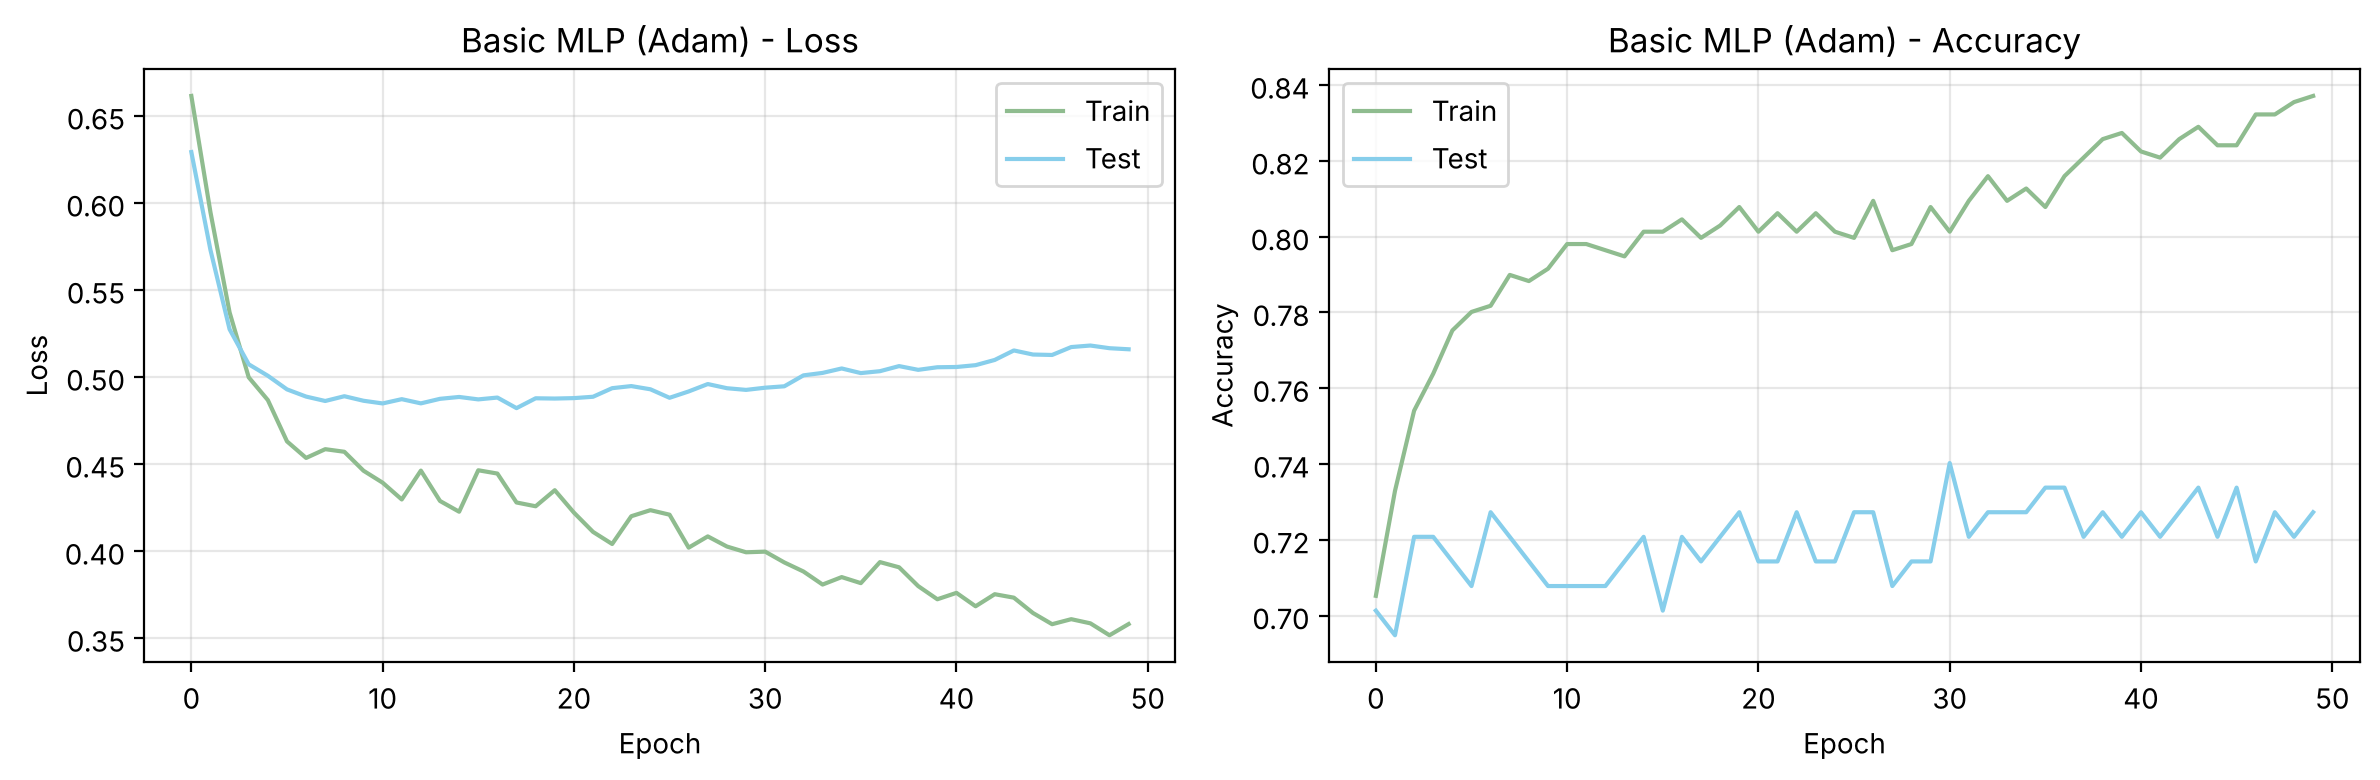

In [8]:
# 기본 모델 학습 (Adam 옵티마이저)
print("=" * 50)                                        # 구분선
print("기본 MLP 학습 (Adam, lr=0.001)")                 # 제목
print("=" * 50)                                        # 구분선

model = MLP(input_size=8)                              # 새 모델 (가중치 무작위 초기화)
criterion = nn.BCELoss()  # Binary Cross Entropy: 정답이 1인데 확률을 낮게(또는 0인데 높게) 줄수록 큰 벌점
optimizer = optim.Adam(model.parameters(), lr=0.001)   # Adam 옵티마이저, 학습률 0.001

history = train_model(model, train_loader, test_loader, criterion, optimizer, num_epochs=50)  # 50에폭 학습

plot_history(history, "Basic MLP (Adam)")              # 학습 곡선 그리기

---

## Part 4: 옵티마이저 비교 실험

In [9]:
# ============================================
# 옵티마이저 비교 실험
# ============================================

optimizer_configs = {                                   # 이름 → '옵티마이저를 만드는 함수' 사전
    'SGD': lambda params: optim.SGD(params, lr=0.01),                         # 기본 경사하강법
    'SGD+Momentum': lambda params: optim.SGD(params, lr=0.01, momentum=0.9),  # 이전 이동 방향(관성)을 90% 이어받음
    'Adam': lambda params: optim.Adam(params, lr=0.001),                      # 파라미터마다 보폭을 자동 조절
}

results = {}                                            # 옵티마이저별 결과 저장 상자

for opt_name, opt_fn in optimizer_configs.items():      # 옵티마이저를 하나씩 바꿔 가며
    print(f"\n{'='*40}")                                 # 구분선
    print(f"Training with {opt_name}")                  # 현재 실험 이름
    print("="*40)                                       # 구분선

    # 새 모델 생성 (공정한 비교를 위해)
    torch.manual_seed(42)  # [추가] 세 실험 모두 '같은 초기 가중치 + 같은 배치 순서'로 출발 → 차이는 옵티마이저 때문만 남음
    model = MLP(input_size=8)                           # 새 모델
    criterion = nn.BCELoss()                            # 손실 함수
    optimizer = opt_fn(model.parameters())              # 이 모델의 파라미터를 업데이트할 옵티마이저 생성

    history = train_model(model, train_loader, test_loader,
                          criterion, optimizer, num_epochs=50)   # 50에폭 학습

    results[opt_name] = {                               # 결과 저장
        'history': history,                             # 에폭별 기록
        'final_acc': history['test_acc'][-1]            # 마지막 에폭의 테스트 정확도
    }

    print(f"Final Test Accuracy: {history['test_acc'][-1]:.4f}")  # 최종 정확도 출력


Training with SGD


Epoch [10/50] Train Loss: 0.6078, Test Acc: 0.6494
Epoch [20/50] Train Loss: 0.5650, Test Acc: 0.6623


Epoch [30/50] Train Loss: 0.5092, Test Acc: 0.7273


Epoch [40/50] Train Loss: 0.5050, Test Acc: 0.7078
Epoch [50/50] Train Loss: 0.4816, Test Acc: 0.6948
Final Test Accuracy: 0.6948

Training with SGD+Momentum


Epoch [10/50] Train Loss: 0.4462, Test Acc: 0.7403


Epoch [20/50] Train Loss: 0.4475, Test Acc: 0.7403
Epoch [30/50] Train Loss: 0.4014, Test Acc: 0.7273


... (3 outputs left out)

Epoch [20/50] Train Loss: 0.4380, Test Acc: 0.7403


Epoch [30/50] Train Loss: 0.3913, Test Acc: 0.7338


Epoch [40/50] Train Loss: 0.3961, Test Acc: 0.7078


Epoch [50/50] Train Loss: 0.3554, Test Acc: 0.7143
Final Test Accuracy: 0.7143


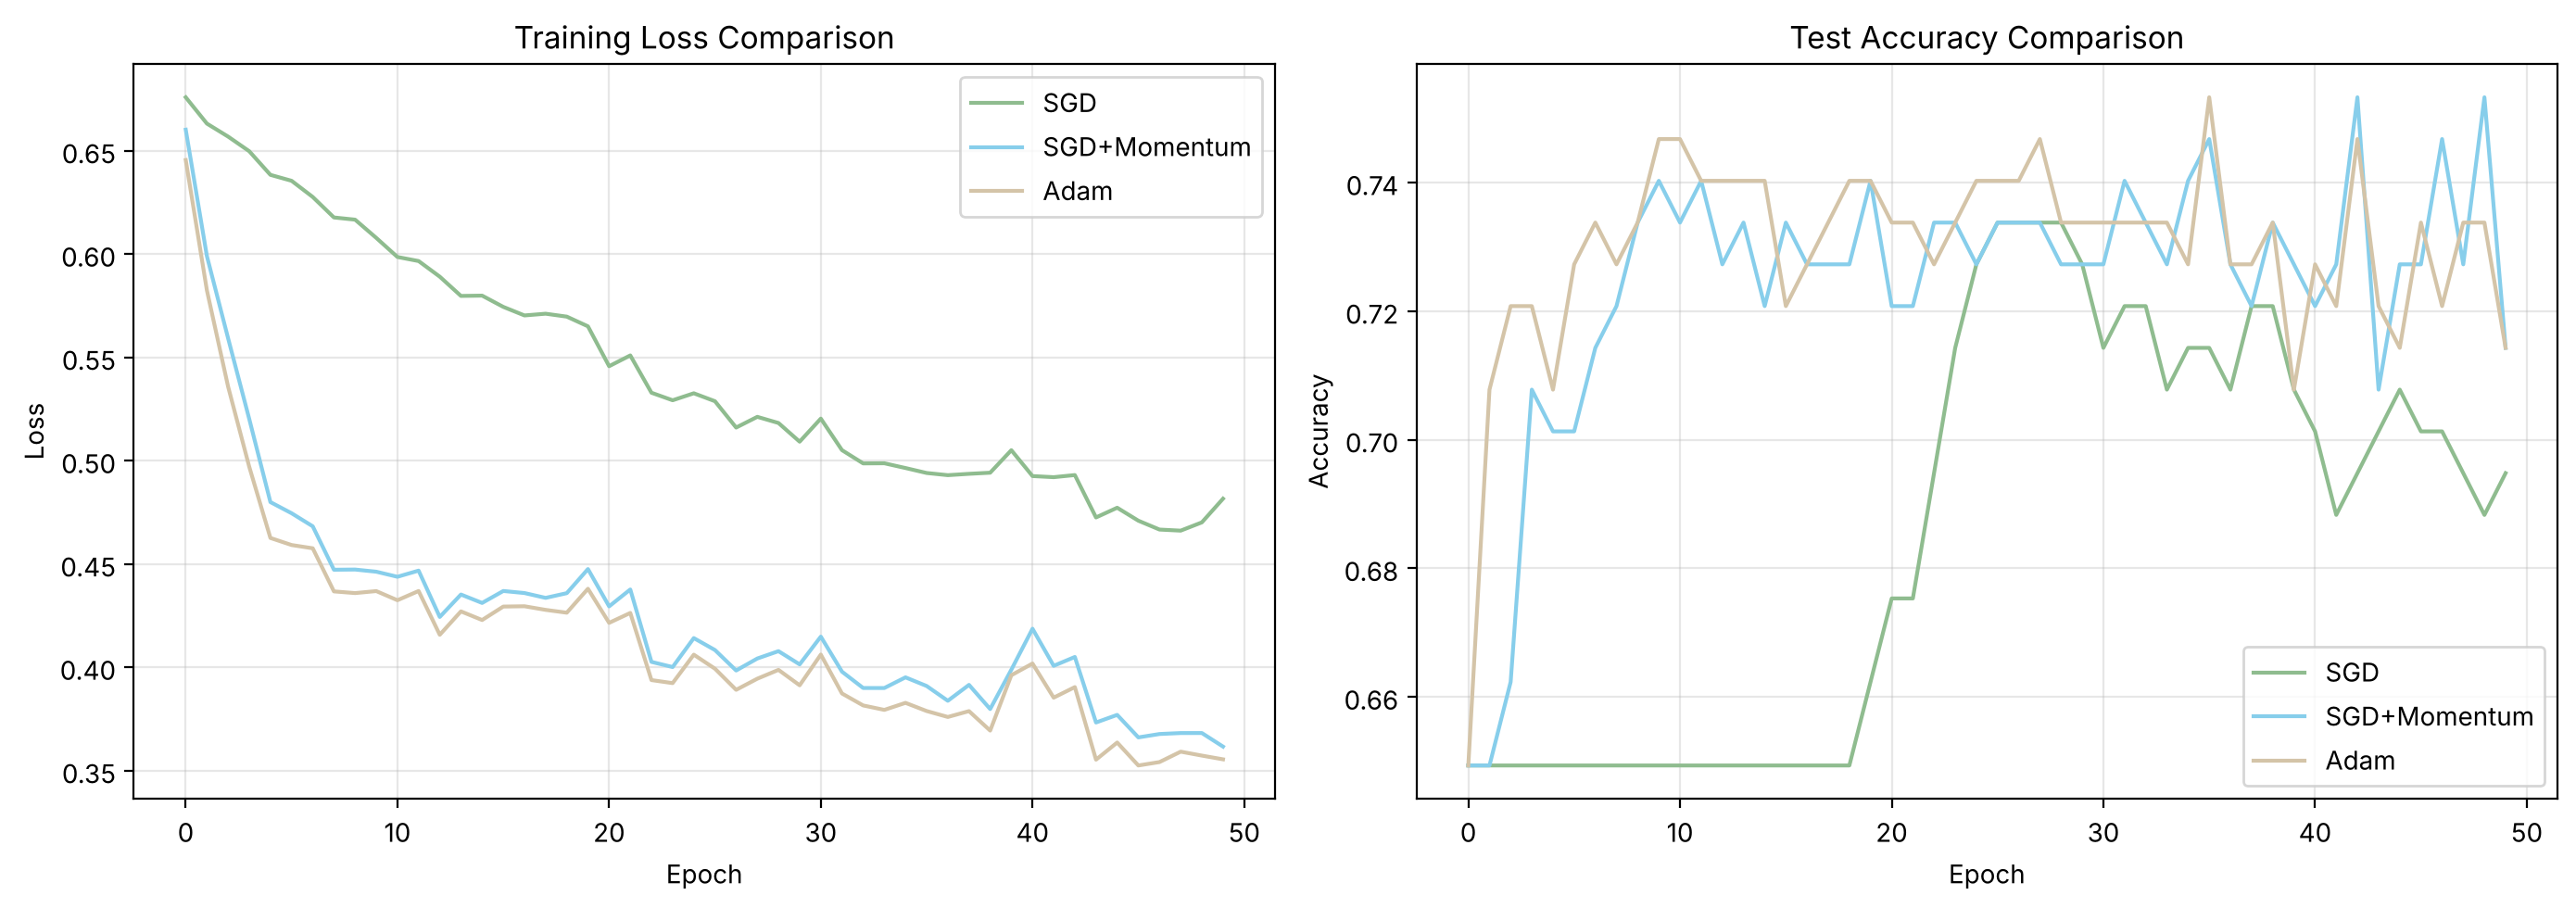


옵티마이저 성능 비교
SGD             | Test Acc: 0.6948
SGD+Momentum    | Test Acc: 0.7143
Adam            | Test Acc: 0.7143


In [10]:
# 옵티마이저 비교 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))         # 왼쪽: 학습 손실, 오른쪽: 테스트 정확도

colors = ['#8FBC8F', '#87CEEB', '#D4C4A8']              # 옵티마이저별 색

# Train Loss 비교
for i, (name, result) in enumerate(results.items()):    # 옵티마이저별로
    axes[0].plot(result['history']['train_loss'], label=name, color=colors[i])  # 학습 손실 곡선
axes[0].set_title('Training Loss Comparison')           # 제목
axes[0].set_xlabel('Epoch')                             # x축
axes[0].set_ylabel('Loss')                              # y축
axes[0].legend()                                        # 범례
axes[0].grid(True, alpha=0.3)                           # 격자

# Test Accuracy 비교
for i, (name, result) in enumerate(results.items()):    # 옵티마이저별로
    axes[1].plot(result['history']['test_acc'], label=name, color=colors[i])    # 테스트 정확도 곡선
axes[1].set_title('Test Accuracy Comparison')           # 제목
axes[1].set_xlabel('Epoch')                             # x축
axes[1].set_ylabel('Accuracy')                          # y축
axes[1].legend()                                        # 범례
axes[1].grid(True, alpha=0.3)                           # 격자

plt.tight_layout()                                      # 간격 정리
plt.show()                                              # 출력

# 결과 요약
print("\n" + "=" * 40)
print("옵티마이저 성능 비교")
print("=" * 40)
for name, result in results.items():                    # 옵티마이저별 최종 정확도 출력
    print(f"{name:15} | Test Acc: {result['final_acc']:.4f}")

### 🔍 수치로 확인하기: "얼마나 빨리" 내려가나?

그래프만 보면 애매할 수 있어서, **수렴 속도**를 숫자로 비교합니다. 기준은 ① 특정 에폭 시점의 학습 손실, ② 학습 손실이 처음으로 **0.50 아래**로 내려간 에폭, ③ 처음부터 몇 에폭 동안 테스트 정확도가 **기준선**(모두 '비당뇨'로 찍었을 때의 정확도)에 머물렀는지, ④ 테스트 손실이 가장 낮았던 에폭입니다.

In [11]:
THRESHOLD = 0.50                                        # 수렴 속도 비교 기준 손실값
majority_acc = (y_test == 0).mean()                     # '전부 0(비당뇨)'으로만 찍었을 때의 정확도 = 기준선
print(f"기준선(전부 비당뇨로 예측할 때의 정확도): {majority_acc:.4f}\n")

print(f"{'옵티마이저':<14} | {'loss@1':>7} | {'loss@10':>7} | {'loss@50':>7} | {'<0.50 도달':>9} | {'기준선 정체':>7} | {'최저 Test Loss(에폭)':>18} | {'최종 Test Acc':>11}")
print("-" * 110)
for name, result in results.items():                    # 옵티마이저별로
    h = result['history']                               # 에폭별 기록 꺼내기
    tl = h['train_loss']                                # 학습 손실 리스트 (0번째 = 1에폭)
    reach = next((e + 1 for e, v in enumerate(tl) if v < THRESHOLD), None)  # 처음으로 기준 아래가 된 에폭(없으면 None)
    stuck = next((e for e, a in enumerate(h['test_acc']) if a > majority_acc + 1e-9), len(h['test_acc']))  # 처음부터 몇 에폭 동안 기준선에 머물렀는지
    best_e = int(np.argmin(h['test_loss']))             # 테스트 손실이 가장 낮은 위치(0부터 시작)
    reach_txt = f"{reach}에폭" if reach else "도달 못 함"  # 표에 쓸 글자
    print(f"{name:<14} | {tl[0]:>7.4f} | {tl[9]:>7.4f} | {tl[49]:>7.4f} | {reach_txt:>9} | {stuck:>6}에폭 | "
          f"{h['test_loss'][best_e]:>10.4f} ({best_e + 1:>2}에폭) | {h['test_acc'][-1]:>11.4f}")

기준선(전부 비당뇨로 예측할 때의 정확도): 0.6494

옵티마이저          |  loss@1 | loss@10 | loss@50 |  <0.50 도달 |  기준선 정체 |   최저 Test Loss(에폭) | 최종 Test Acc
--------------------------------------------------------------------------------------------------------------
SGD            |  0.6758 |  0.6078 |  0.4816 |      33에폭 |     19에폭 |     0.4854 (50에폭) |      0.6948
SGD+Momentum   |  0.6602 |  0.4462 |  0.3616 |       5에폭 |      2에폭 |     0.4705 (11에폭) |      0.7143
Adam           |  0.6455 |  0.4369 |  0.3554 |       4에폭 |      1에폭 |     0.4704 (11에폭) |      0.7143


### [필수] 과제 4-1: 옵티마이저 비교 분석

위 실험 결과를 보고 답하세요:

1. SGD와 Adam 중 어떤 옵티마이저가 더 빠르게 수렴하나요?
   - 답변: **Adam이 훨씬 빠르게 수렴합니다.** 학습 손실이 처음으로 0.50 아래로 내려간 시점이 Adam은 **4에폭**, SGD는 **33에폭**이었고, 10에폭 시점 학습 손실도 Adam 0.4369 vs SGD 0.6078로 차이가 컸습니다. SGD는 처음 **19에폭** 동안 테스트 정확도가 기준선 0.6494(테스트 154명 중 비당뇨 100명만 맞힌 값 = '전부 당뇨 아님'으로 찍는 수준)에 머물렀고, 테스트 손실 최저점도 마지막 50에폭이라 50에폭이 끝날 때까지 아직 내려가는 중이었습니다. Adam은 파라미터마다 지금까지의 기울기 크기를 보고 보폭(학습률)을 자동으로 조절하기 때문에 같은 50에폭 안에서 훨씬 빨리 좋은 지점에 도달합니다.

2. Momentum을 추가하면 어떤 변화가 있나요? (SGD vs SGD+Momentum)
   - 답변: **수렴이 크게 빨라졌습니다.** 같은 학습률(0.01)인데도 학습 손실이 0.50 아래로 내려간 시점이 SGD 33에폭 → SGD+Momentum **5에폭**으로 당겨졌고, 10에폭 시점 손실도 0.6078 → 0.4462로 Adam(0.4369)과 거의 비슷해졌습니다. 최종 테스트 정확도도 0.6948 → 0.7143으로 올랐습니다(154명 기준 3명 차이). Momentum은 직전까지 움직이던 방향을 90%(`momentum=0.9`) 이어받는 '관성'을 만들어서, 같은 방향으로 계속 내려가는 구간에서는 점점 가속하고 지그재그로 흔들리는 성분은 서로 상쇄되기 때문입니다.
   - 💡 비유: 그냥 SGD는 한 걸음마다 멈춰 서서 경사를 다시 살피는 등산객이고, Momentum은 굴러 내려가던 속도를 유지하는 공이라 완만한 구간도 금방 지나갑니다.
   - 덧붙여, SGD+Momentum과 Adam 모두 테스트 손실은 **11에폭**에서 가장 낮았고 그 뒤로는 학습 손실만 계속 내려갔습니다(50에폭 0.36 수준). 더 오래 학습한다고 좋아지지 않는 '과적합' 신호이고, 3일차의 Early Stopping이 필요한 이유입니다.

---

## Part 5: [도전] 학습률 실험

학습률(Learning Rate)이 학습에 미치는 영향을 실험해보세요.


Adam (lr=0.1)


Epoch [10/50] Train Loss: 0.4659, Test Acc: 0.7143


Epoch [20/50] Train Loss: 0.4703, Test Acc: 0.7338


Epoch [30/50] Train Loss: 0.4407, Test Acc: 0.7273


Epoch [40/50] Train Loss: 0.4110, Test Acc: 0.7143


Epoch [50/50] Train Loss: 0.4655, Test Acc: 0.6948

Adam (lr=0.01)


... (11 outputs left out)

Epoch [20/50] Train Loss: 0.5623, Test Acc: 0.7143


Epoch [30/50] Train Loss: 0.5039, Test Acc: 0.7208


Epoch [40/50] Train Loss: 0.4982, Test Acc: 0.7143


Epoch [50/50] Train Loss: 0.4755, Test Acc: 0.7078


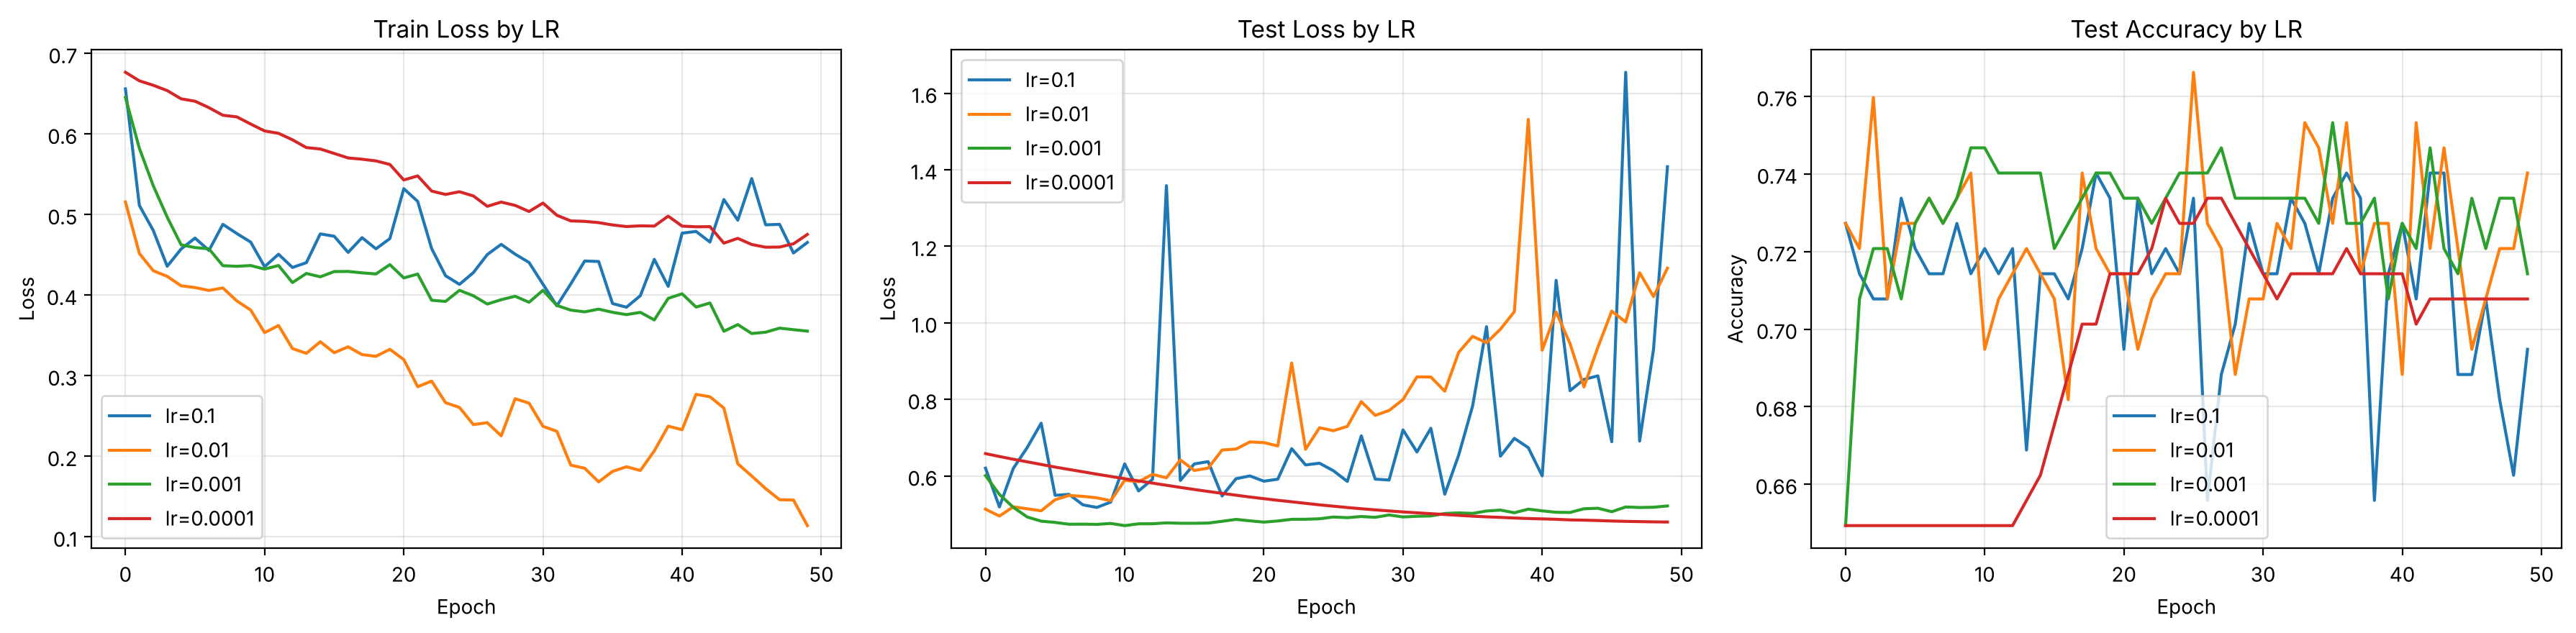


     학습률 | 최종 Train Loss |   최저 Test Loss(에폭) | 최종 Test Loss | 최종 Test Acc
--------------------------------------------------------------------------------
     0.1 |        0.4655 |     0.5178 ( 9에폭) |       1.4079 |      0.6948
    0.01 |        0.1141 |     0.4954 ( 2에폭) |       1.1429 |      0.7403
   0.001 |        0.3554 |     0.4704 (11에폭) |       0.5218 |      0.7143
  0.0001 |        0.4755 |     0.4798 (50에폭) |       0.4798 |      0.7078


In [12]:
# [도전 과제] 학습률 비교 실험
# 옵티마이저는 Adam으로 고정하고 '학습률(한 번에 가중치를 얼마나 크게 고칠지)'만 바꿔서 비교합니다.

learning_rates = [0.1, 0.01, 0.001, 0.0001]             # 10배씩 차이 나는 학습률 4개

lr_results = {}                                         # 학습률별 기록 저장 상자
for lr in learning_rates:                               # 학습률을 하나씩 바꿔 가며
    print(f"\n{'='*40}\nAdam (lr={lr})\n{'='*40}")      # 구분 출력
    torch.manual_seed(42)                               # 같은 초기 가중치·배치 순서 → 학습률만 다르게
    model = MLP(input_size=8)                           # 새 모델
    criterion = nn.BCELoss()                            # 손실 함수
    optimizer = optim.Adam(model.parameters(), lr=lr)   # 학습률만 바꾼 Adam
    lr_results[lr] = train_model(model, train_loader, test_loader,
                                 criterion, optimizer, num_epochs=50)  # 50에폭 학습 후 기록 저장

# 시각화: 학습 손실 / 테스트 손실 / 테스트 정확도
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))       # 그림 3칸
for lr, h in lr_results.items():                        # 학습률별로 곡선 3개씩
    axes[0].plot(h['train_loss'], label=f'lr={lr}')     # 학습 손실
    axes[1].plot(h['test_loss'], label=f'lr={lr}')      # 테스트 손실
    axes[2].plot(h['test_acc'], label=f'lr={lr}')       # 테스트 정확도
for ax, title, ylabel in zip(axes,                      # 세 칸에 제목·축 이름 붙이기
                             ['Train Loss by LR', 'Test Loss by LR', 'Test Accuracy by LR'],
                             ['Loss', 'Loss', 'Accuracy']):
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel)  # 제목·축
    ax.legend(); ax.grid(True, alpha=0.3)               # 범례·격자
plt.tight_layout()                                      # 간격 정리
plt.show()                                              # 출력

# 요약 표
print(f"\n{'학습률':>8} | {'최종 Train Loss':>13} | {'최저 Test Loss(에폭)':>18} | {'최종 Test Loss':>12} | {'최종 Test Acc':>11}")
print("-" * 80)
for lr, h in lr_results.items():                        # 학습률별 요약
    best_e = int(np.argmin(h['test_loss']))             # 테스트 손실이 가장 낮았던 에폭(0부터)
    print(f"{lr:>8} | {h['train_loss'][-1]:>13.4f} | {h['test_loss'][best_e]:>10.4f} ({best_e + 1:>2}에폭) | "
          f"{h['test_loss'][-1]:>12.4f} | {h['test_acc'][-1]:>11.4f}")

#### 📝 도전 과제 결과 해석

옵티마이저는 Adam으로 고정하고 학습률만 바꿨습니다(같은 시드 → 같은 초기 가중치).

| 학습률 | 관찰한 결과 (위 요약 표·그래프) | 진단 |
|:--:|------|------|
| 0.1 | 10에폭마다 찍힌 학습 손실이 0.4659 → 0.4703 → 0.4407 → 0.4110 → 0.4655로 오르내리고, 테스트 손실은 9에폭(0.5178)이 최저였다가 크게 튀며 최종 1.4079 | **너무 큼**: 보폭이 커서 골짜기 바닥을 계속 건너뜀 → 불안정 |
| 0.01 | 학습 손실은 0.1141까지 가장 많이 내려갔지만, 테스트 손실은 **2에폭**(0.4954)이 최저였고 이후 계속 올라 최종 1.1429 | **빠르지만 과적합**: 학습 데이터를 외우는 중 |
| 0.001 | 테스트 손실 최저값이 네 가지 중 가장 낮고(0.4704, 11에폭) 최종 0.5218로 비교적 안정 | **적당함**: 이 데이터·모델에서 가장 균형 잡힘 |
| 0.0001 | 50에폭 후에도 학습 손실 0.4755, 테스트 손실이 마지막 50에폭(0.4798)까지 계속 감소 중 | **너무 작음**: 아직 수렴 전 → 에폭을 늘려야 함 |

- ⚠️ 흥미로운 점: 최종 테스트 **정확도**는 lr=0.01이 0.7403으로 가장 높지만, 같은 모델의 테스트 **손실**은 1.1429로 매우 큽니다. 정확도는 '0.5 기준으로 맞았나/틀렸나'만 보지만, 손실은 '틀린 답에 얼마나 확신했나'까지 벌점을 주기 때문입니다. lr=0.01 모델은 틀릴 때 아주 자신 있게 틀리는(과신하는) 상태라, 확률 자체가 중요한 의료 예측에는 위험합니다. 또 테스트가 154명뿐이라 0.7403과 0.7143의 차이는 **4명**(114명 vs 110명)이어서 우연의 영향도 큽니다.
- 결론: 학습률은 **보폭**입니다. 너무 크면 바닥을 건너뛰며 튀고(0.1), 너무 작으면 정해진 에폭 안에 바닥까지 못 갑니다(0.0001). 여기서는 Adam의 기본값 0.001이 가장 균형 잡힌 선택이었습니다.

---

## Part 6: [필수] PyTorch 학습 루프 코드 필사

노션 2일차 페이지의 **(필수) 과제 "PyTorch 학습 루프 코드 필사 업로드 하기"**입니다. 위에서는 `train_model` 함수 안에 숨어 있던 학습 루프를, 이번에는 **데이터 준비부터 평가까지 한 셀에 처음부터 끝까지** 써 내려갔습니다.

| 순서 | 단계 | 한 줄 요약 |
|:--:|------|------|
| ① | `Dataset` | "데이터 **한 개**를 어떻게 꺼낼지" 규칙 정의 (`__len__`, `__getitem__`) |
| ② | `DataLoader` | 데이터셋을 **미니배치**로 잘라 순서대로 공급 (학습 때는 섞기) |
| ③ | 모델 | `nn.Module` 상속 → `__init__`에서 층 준비, `forward`에서 통과 경로 정의 |
| ④ | 손실 함수 | 예측이 정답과 얼마나 다른지 숫자 하나로 계산 |
| ⑤ | 옵티마이저 | 기울기를 보고 가중치를 고치는 규칙 (Adam 등) |
| ⑥ | 학습 루프 | `zero_grad → forward → loss → backward → step` (5단계 주문) |
| ⑦ | 평가 | `model.eval()` + `torch.no_grad()` 로 기울기 없이 성능만 측정 |

In [13]:
# ==========================================================
# [필수 과제] PyTorch 학습 루프 필사
# 흐름: ① Dataset → ② DataLoader → ③ 모델 → ④ 손실 함수 → ⑤ 옵티마이저 → ⑥ 학습 루프 → ⑦ 평가
# ==========================================================
import torch                                       # 파이토치 본체 (텐서 연산 + 자동 미분)
import torch.nn as nn                              # 층·손실 함수 모음
import torch.optim as optim                        # 옵티마이저 모음
from torch.utils.data import Dataset, DataLoader   # 데이터를 담는 틀(Dataset)과 배치 공급기(DataLoader)

torch.manual_seed(42)                              # 재현성을 위해 난수 고정

# ---------- ① Dataset: "샘플 한 개를 꺼내 주는 규칙" ----------
class DiabetesDataset(Dataset):                    # 파이토치 Dataset을 상속해 나만의 데이터셋 정의
    def __init__(self, X, y):                      # 데이터셋을 만들 때 한 번 실행
        self.X = torch.tensor(X, dtype=torch.float32)               # 입력 특성 → 실수 텐서 [N, 8]
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)  # 정답 → 실수 텐서 [N, 1]

    def __len__(self):                             # 전체 샘플 개수 (DataLoader가 배치 수를 계산할 때 사용)
        return len(self.X)

    def __getitem__(self, idx):                    # idx번째 샘플 하나를 (입력, 정답)으로 반환
        return self.X[idx], self.y[idx]

train_ds = DiabetesDataset(X_train_scaled, y_train)   # 학습 데이터셋 (Part 1에서 표준화한 값 사용)
test_ds = DiabetesDataset(X_test_scaled, y_test)      # 테스트 데이터셋

# ---------- ② DataLoader: 미니배치로 잘라서 공급 ----------
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)    # 학습: 32개씩, 에폭마다 섞기
test_dl = DataLoader(test_ds, batch_size=32, shuffle=False)     # 평가: 섞지 않음

# ---------- ③ 모델 ----------
class DiabetesNet(nn.Module):                      # 모델 설계도
    def __init__(self):
        super().__init__()                         # 부모 클래스 초기화 (필수)
        self.layers = nn.Sequential(               # 층을 순서대로 연결
            nn.Linear(8, 16),                      # 입력 8 → 은닉 16
            nn.ReLU(),                             # 비선형 활성화
            nn.Linear(16, 1),                      # 은닉 16 → 출력 1 (로짓: 시그모이드 적용 전 점수)
        )

    def forward(self, x):                          # 순전파 경로
        return self.layers(x)                      # 로짓 반환 (시그모이드는 손실 함수 안에서 처리)

net = DiabetesNet()                                # 모델 객체 생성

# ---------- ④ 손실 함수 ----------
loss_fn = nn.BCEWithLogitsLoss()                   # Sigmoid + BCE가 합쳐진 손실 → 수치적으로 더 안정적

# ---------- ⑤ 옵티마이저 ----------
opt = optim.Adam(net.parameters(), lr=0.01)        # 모델 파라미터를 Adam으로 업데이트 (학습률 0.01)

# ---------- ⑥ 학습 루프 ----------
num_epochs = 30                                    # 전체 데이터를 30번 반복
for epoch in range(1, num_epochs + 1):             # 1 ~ 30 에폭
    net.train()                                    # [학습 모드]
    running_loss = 0.0                             # 에폭 손실 합계
    for xb, yb in train_dl:                        # 미니배치 하나씩
        opt.zero_grad()                            # (1) 이전 기울기 초기화
        logits = net(xb)                           # (2) 순전파: 예측 점수
        loss = loss_fn(logits, yb)                 # (3) 손실 계산
        loss.backward()                            # (4) 역전파: 기울기 계산
        opt.step()                                 # (5) 가중치 업데이트
        running_loss += loss.item() * xb.size(0)   # 배치 평균 손실 × 배치 크기 → 샘플 단위 합계
    train_loss = running_loss / len(train_ds)      # 에폭 평균 학습 손실

    # ---------- ⑦ 평가 ----------
    net.eval()                                     # [평가 모드] Dropout 끄기, BatchNorm 고정
    correct, test_loss_sum = 0, 0.0                # 맞힌 수, 손실 합계
    with torch.no_grad():                          # 기울기 계산 끄기
        for xb, yb in test_dl:                     # 테스트 배치 반복
            logits = net(xb)                       # 예측 점수
            test_loss_sum += loss_fn(logits, yb).item() * xb.size(0)  # 손실 누적
            preds = (torch.sigmoid(logits) > 0.5).float()  # 점수 → 확률 → 0/1 예측
            correct += (preds == yb).sum().item()          # 맞힌 개수 누적
    test_loss = test_loss_sum / len(test_ds)       # 평균 테스트 손실
    test_acc = correct / len(test_ds)              # 테스트 정확도

    if epoch % 5 == 0:                             # 5에폭마다 진행 상황 출력
        print(f"[{epoch:2d}/{num_epochs}] train_loss={train_loss:.4f} | "
              f"test_loss={test_loss:.4f} | test_acc={test_acc:.4f}")

[ 5/30] train_loss=0.4512 | test_loss=0.4874 | test_acc=0.7273


[10/30] train_loss=0.4371 | test_loss=0.4926 | test_acc=0.7273
[15/30] train_loss=0.4257 | test_loss=0.5035 | test_acc=0.7273


[20/30] train_loss=0.4195 | test_loss=0.5009 | test_acc=0.7143
[25/30] train_loss=0.4139 | test_loss=0.5070 | test_acc=0.7273
[30/30] train_loss=0.4119 | test_loss=0.5022 | test_acc=0.7338


✍️ **필사하며 기억할 포인트**
- 학습 5단계 주문: **`zero_grad()` → `model(x)` → `loss_fn()` → `backward()` → `step()`**. 순서가 바뀌면(예: `zero_grad`를 빼먹으면) 기울기가 배치마다 계속 쌓여 학습이 엉망이 됩니다.
- 평가 2종 세트: **`model.eval()`**(Dropout·BatchNorm을 평가용으로 전환) + **`with torch.no_grad():`**(기울기 계산 끄기).
- 이번 필사에서는 위 Part 2~5와 달리 출력층에 Sigmoid를 두지 않고 **`BCEWithLogitsLoss`**를 썼습니다. 그래서 정확도를 계산할 때는 `torch.sigmoid(logits)`로 확률을 직접 만들어 줘야 합니다.

---

## 2일차 학습 정리

오늘 배운 핵심 내용을 체크해보세요:

- [x] PyTorch로 MLP 모델 구현 (`nn.Module`, `nn.Sequential`)
- [x] 학습 루프: 순전파 -> 손실 계산 -> 역전파 -> 가중치 업데이트
- [x] `BCELoss`: 이진 분류용 손실함수
- [x] SGD vs Adam 옵티마이저의 차이
- [x] Momentum의 역할

---

## 수고하셨습니다!

### 제출 전 체크리스트
- [x] 과제 2-1 (MLP 구조 이해) 답변 작성
- [x] 과제 4-1 (옵티마이저 비교) 답변 작성
- [x] [선택] 도전 과제 (학습률 실험)
- [x] (필수) PyTorch 학습 루프 코드 필사 → Part 6

## 📌 핵심 정리

- **MLP** = `nn.Linear` + 활성화 함수를 여러 층 쌓은 것입니다. `nn.Linear(n, m)`의 파라미터는 `n×m + m`개 → 이 모델은 총 **2,689개**입니다.
- **학습 루프 5단계**: `zero_grad → forward → loss → backward → step`. 평가는 `model.eval()` + `torch.no_grad()` (Part 6 필사).
- **정확도의 기준선부터 확인하기**: 테스트 154명 중 100명이 비당뇨라 '전부 0'으로만 찍어도 0.6494입니다. 이번 모델들의 테스트 정확도(대부분 0.69~0.74)는 이 기준선과 비교해서 해석해야 합니다.
- **옵티마이저**: 학습 손실 0.50 도달 기준 Adam 4에폭 ≈ SGD+Momentum 5에폭 ≪ SGD 33에폭. Momentum(관성)과 Adam(파라미터별 보폭 자동 조절)이 수렴을 크게 앞당깁니다.
- **학습률**: 0.1 불안정, 0.01 과적합, 0.001 균형, 0.0001 미수렴 → 학습률은 가장 먼저 튜닝할 하이퍼파라미터입니다.
- **주의할 점**: 이번 실습은 학습 중 성능 확인에도 테스트 세트를 썼습니다. 원래 테스트 세트는 마지막에 한 번만 보는 '성적표'라서, 3일차처럼 **검증(Validation) 세트**를 따로 두고 그걸로 모델·에폭·학습률을 고르는 것이 올바른 방법입니다.